# EXPERIMENT NOTEBOOK: PERBANDINGAN MODEL RANDOM FOREST
## Evaluasi 3 Kriteria Impurity: GINI vs SHANNON ENTROPY vs LOG LOSS
### Proyek PBL: Sistem Prediksi Risiko Burnout (AntiBurnout ML Codex)

## 0. Setup Awal & Konfigurasi Lingkungan

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputPerbandinganRandomForest'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Direktori artefak siap: {OUTPUT_DIR}")

Direktori artefak siap: outputPerbandinganRandomForest


## 1. Load Dataset & Stratified Sampling (5.000 Data)

In [2]:
df_raw = pd.read_csv('burnout_dataset1.csv')
print(f'Jumlah data awal: {len(df_raw):,} baris')

# Stratified sampling 5.000 data sesuai PRD Bagian 5 (random_state=42)
df, _ = train_test_split(
    df_raw,
    train_size=5000,
    random_state=42,
    stratify=df_raw['Burnout_Risk']
)
df = df.reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df):,} baris')

print('\nDistribusi Kelas Target Awal (Burnout_Risk):')
print(df['Burnout_Risk'].value_counts())

Jumlah data awal: 50,000 baris
Jumlah data setelah sampling: 5,000 baris

Distribusi Kelas Target Awal (Burnout_Risk):
Burnout_Risk
Low         2537
Moderate    1478
High         985
Name: count, dtype: int64


## 2. Pemeriksaan X dan y (Strict Feature Policy: Mencegah Data Leakage)

In [3]:
y = df['Burnout_Risk'].copy()

# Identifikasi kolom numerik dan kategorikal
numeric_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Drop kolom ID dan target leakage fatal
# 1. Person_ID: identifier non-prediktif
# 2. Burnout_Score: deterministik terhadap Burnout_Risk (<40 Low, 40-64 Mod, >=65 High)
# 3. Mental_Health_Status: leakage fatal (Healthy=100% Low, Needs Attention=100% Mod)
numeric_cols = numeric_cols.drop(['Person_ID', 'person_id', 'Burnout_Score'], errors='ignore')
categorical_cols = categorical_cols.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_features = list(numeric_cols) + list(categorical_cols)
X = df[selected_features].copy()

# Encoding Ordinal Kategorikal
encoding_maps = {
    'Remote_Work': {'No': 0, 'Hybrid': 1, 'Yes': 2},
    'Sleep_Quality': {'Excellent': 0, 'Good': 1, 'Average': 2, 'Poor': 3},
    'Stress_Level': {'Low': 0, 'Moderate': 1, 'High': 2},
    'Exercise_Frequency': {'Daily': 0, 'Weekly': 1, 'Rarely': 2, 'Never': 3},
    'Alcohol_Consumption': {'No': 0, 'Yes': 1},
    'Smoking': {'No': 0, 'Yes': 1},
    'Healthy_Diet': {'No': 1, 'Yes': 0},
    'Chronic_Stress': {'No': 0, 'Yes': 1},
    'Family_History_Mental_Illness': {'No': 0, 'Yes': 1},
    'Therapy_Attendance': {'No': 1, 'Yes': 0},
    'Support_System': {'Poor': 3, 'Average': 2, 'Good': 1, 'Excellent': 0}
}

for col, mapping in encoding_maps.items():
    if col in X.columns:
        X[col] = X[col].map(mapping)

# Encoding Target Variable
target_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
y = y.map(target_mapping)

# Imputasi Missing Values sebelum split
X = X.fillna(X.mean())

print(f'Dimensi Fitur X: {X.shape}')
print(f'Dimensi Target y: {y.shape}')
print(f'Jumlah Missing Values pada X: {X.isnull().sum().sum()}')

Dimensi Fitur X: (5000, 30)
Dimensi Target y: (5000,)
Jumlah Missing Values pada X: 0


## 3. Stratified Train-Test Split 80:20 & Standardisasi

In [4]:
# Split 80% Train Set (4000) dan 20% Holdout Test Set (1000) secara terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Imputer dan Scaler di-fit HANYA pada data latih (mencegah Data Leakage)
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test.index)

print(f'Training Set (80%): {X_train.shape[0]} baris, {X_train.shape[1]} fitur')
print(f'Testing Set  (20%): {X_test.shape[0]} baris, {X_test.shape[1]} fitur')
print('\nDistribusi Target pada Training Set:')
print(y_train.value_counts(normalize=True).round(4))
print('\nDistribusi Target pada Testing Set:')
print(y_test.value_counts(normalize=True).round(4))

Training Set (80%): 4000 baris, 30 fitur
Testing Set  (20%): 1000 baris, 30 fitur

Distribusi Target pada Training Set:
Burnout_Risk
0    0.5075
1    0.2955
2    0.1970
Name: proportion, dtype: float64

Distribusi Target pada Testing Set:
Burnout_Risk
0    0.507
1    0.296
2    0.197
Name: proportion, dtype: float64


## 4. Stratified 5-Fold Cross-Validation pada 80% Training Set
### Membandingkan Model 1 (Gini), Model 2 (Entropy), dan Model 3 (Log Loss)

In [5]:
models = {
    'Random Forest GINI': RandomForestClassifier(
        criterion='gini',
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    'Random Forest ENTROPY': RandomForestClassifier(
        criterion='entropy',
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    'Random Forest LOG LOSS': RandomForestClassifier(
        criterion='log_loss',
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_summary = []
all_cv_results = {}

for name, model_obj in models.items():
    print(f"Menjalankan 5-Fold CV untuk: {name}...")
    
    tracemalloc.start()
    t0 = time.process_time()
    
    cv_res = cross_validate(
        model_obj,
        X_train,
        y_train,
        cv=cv,
        scoring=cv_scoring
    )
    
    elapsed = time.process_time() - t0
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    peak_mb = peak / (1024 * 1024)
    
    all_cv_results[name] = cv_res
    
    cv_summary.append({
        'Model': name,
        'Criterion': model_obj.criterion,
        'CV_Accuracy_Mean': round(cv_res['test_accuracy'].mean(), 4),
        'CV_Accuracy_Std': round(cv_res['test_accuracy'].std(), 4),
        'CV_F1_Macro_Mean': round(cv_res['test_f1_macro'].mean(), 4),
        'CV_Precision_Macro_Mean': round(cv_res['test_precision_macro'].mean(), 4),
        'CV_Recall_Macro_Mean': round(cv_res['test_recall_macro'].mean(), 4),
        'CV_F1_Weighted_Mean': round(cv_res['test_f1_weighted'].mean(), 4),
        'CV_Total_Time_s': round(elapsed, 4),
        'CV_Peak_Memory_MB': round(peak_mb, 4)
    })

df_cv_comparison = pd.DataFrame(cv_summary)
display(df_cv_comparison)

Menjalankan 5-Fold CV untuk: Random Forest GINI...
Menjalankan 5-Fold CV untuk: Random Forest ENTROPY...
Menjalankan 5-Fold CV untuk: Random Forest LOG LOSS...


,Model,Criterion,CV_Accuracy_Mean,CV_Accuracy_Std,CV_F1_Macro_Mean,CV_Precision_Macro_Mean,CV_Recall_Macro_Mean,CV_F1_Weighted_Mean,CV_Total_Time_s,CV_Peak_Memory_MB
0,Random Forest GINI,gini,0.8092,0.0066,0.7925,0.7992,0.7888,0.8117,9.9375,4.7578
1,Random Forest ENTROPY,entropy,0.8080,0.0039,0.7916,0.7989,0.7876,0.8104,9.5312,4.7537
2,Random Forest LOG LOSS,log_loss,0.8080,0.0039,0.7916,0.7989,0.7876,0.8104,9.3906,4.7082


## 5. Pemilihan Konfigurasi Terbaik (Champion Selection based on Mean CV Accuracy)

In [6]:
# Memilih model dengan Mean CV Accuracy tertinggi
champion_row = df_cv_comparison.sort_values(by='CV_Accuracy_Mean', ascending=False).iloc[0]
champion_name = champion_row['Model']
champion_criterion = champion_row['Criterion']
champion_cv_acc = champion_row['CV_Accuracy_Mean']

print('='*70)
print(f"🏆 MODEL PEMENANG (CHAMPION MODEL): {champion_name}")
print(f"Kriteria Impurity : {champion_criterion}")
print(f"Rata-rata Akurasi CV: {champion_cv_acc:.4f} (+/- {champion_row['CV_Accuracy_Std']:.4f})")
print('='*70)

🏆 MODEL PEMENANG (CHAMPION MODEL): Random Forest GINI
Kriteria Impurity : gini
Rata-rata Akurasi CV: 0.8092 (+/- 0.0066)


## 6. Fit Ulang Model Champion pada Seluruh Training Set (80%)
### Serta Fit Semua Model untuk Evaluasi Final pada Holdout Testing Set (20%)

In [7]:
final_eval_results = []
fitted_models = {}
predictions = {}

for name, model_obj in models.items():
    print(f"Melatih ulang {name} pada seluruh 80% Training Set...")
    
    tracemalloc.start()
    t0 = time.process_time()
    
    model_obj.fit(X_train, y_train)
    
    train_time = time.process_time() - t0
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    train_memory_mb = peak / (1024 * 1024)
    
    fitted_models[name] = model_obj
    
    # Prediksi pada Holdout Test Set (20%)
    y_pred = model_obj.predict(X_test)
    predictions[name] = y_pred
    
    # Evaluasi metrik test set
    acc = accuracy_score(y_test, y_pred)
    prec_macro = precision_score(y_test, y_pred, average='macro')
    rec_macro = recall_score(y_test, y_pred, average='macro')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    
    # Ambil CV accuracy mean dari df_cv_comparison
    cv_acc_mean = df_cv_comparison.loc[df_cv_comparison['Model'] == name, 'CV_Accuracy_Mean'].values[0]
    cv_f1_mean = df_cv_comparison.loc[df_cv_comparison['Model'] == name, 'CV_F1_Macro_Mean'].values[0]
    
    final_eval_results.append({
        'Model': name,
        'Criterion': model_obj.criterion,
        'CV_Accuracy_Mean': cv_acc_mean,
        'CV_F1_Macro_Mean': cv_f1_mean,
        'Test_Accuracy': round(acc, 4),
        'Test_Precision_Macro': round(prec_macro, 4),
        'Test_Recall_Macro': round(rec_macro, 4),
        'Test_F1_Macro': round(f1_macro, 4),
        'Test_F1_Weighted': round(f1_weighted, 4),
        'Training_Time_s': round(train_time, 4),
        'Peak_Memory_MB': round(train_memory_mb, 4)
    })

df_final_comparison = pd.DataFrame(final_eval_results)
display(df_final_comparison)

Melatih ulang Random Forest GINI pada seluruh 80% Training Set...
Melatih ulang Random Forest ENTROPY pada seluruh 80% Training Set...
Melatih ulang Random Forest LOG LOSS pada seluruh 80% Training Set...


,Model,Criterion,CV_Accuracy_Mean,CV_F1_Macro_Mean,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro,Test_F1_Weighted,Training_Time_s,Peak_Memory_MB
0,Random Forest GINI,gini,0.8092,0.7925,0.804,0.7857,0.7859,0.7854,0.8061,1.9219,4.2937
1,Random Forest ENTROPY,entropy,0.8080,0.7916,0.803,0.7888,0.7866,0.7870,0.8055,1.8906,4.0796
2,Random Forest LOG LOSS,log_loss,0.8080,0.7916,0.803,0.7888,0.7866,0.7870,0.8055,1.9844,3.9456


## 7. Evaluasi Mendalam Model Champion pada Testing Set (20% Holdout)

In [8]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']
champion_pred = predictions[champion_name]

print(f"=== CLASSIFICATION REPORT: {champion_name} (HOLDOUT TEST SET) ===\n")
print(classification_report(y_test, champion_pred, target_names=target_names, digits=4))

champion_cm = confusion_matrix(y_test, champion_pred)
print("Confusion Matrix Champion:")
print(champion_cm)

=== CLASSIFICATION REPORT: Random Forest GINI (HOLDOUT TEST SET) ===

              precision    recall  f1-score   support

     Low (0)     0.9018    0.8698    0.8855       507
Moderate (1)     0.6572    0.7061    0.6808       296
    High (2)     0.7979    0.7817    0.7897       197

    accuracy                         0.8040      1000
   macro avg     0.7857    0.7859    0.7854      1000
weighted avg     0.8090    0.8040    0.8061      1000

Confusion Matrix Champion:
[[441  66   0]
 [ 48 209  39]
 [  0  43 154]]


## 8. Visualisasi Hasil Eksperimen Komparasi

### 8.1 Perbandingan Akurasi (CV Mean vs Holdout Test)

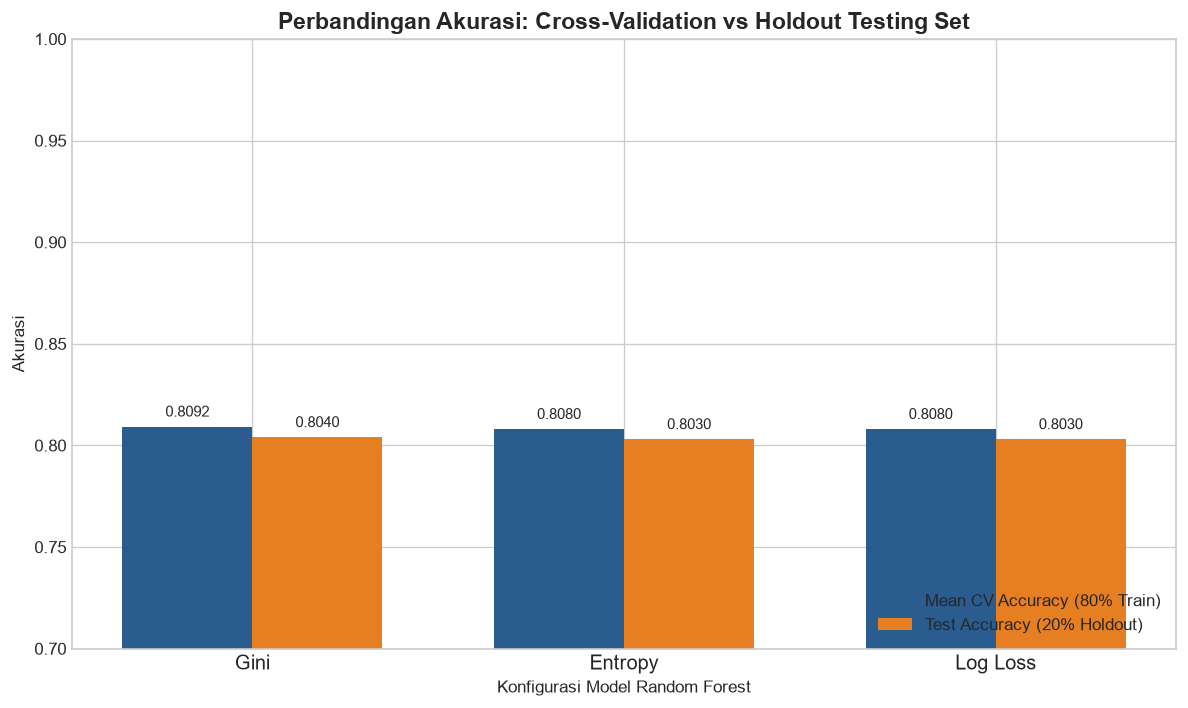

In [9]:
x = np.arange(len(df_final_comparison))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, df_final_comparison['CV_Accuracy_Mean'], width, label='Mean CV Accuracy (80% Train)', color='#2b5c8f')
plt.bar(x + width/2, df_final_comparison['Test_Accuracy'], width, label='Test Accuracy (20% Holdout)', color='#e67e22')

plt.title('Perbandingan Akurasi: Cross-Validation vs Holdout Testing Set', fontsize=14, fontweight='bold')
plt.xlabel('Konfigurasi Model Random Forest')
plt.ylabel('Akurasi')
plt.xticks(x, ['Gini', 'Entropy', 'Log Loss'], fontsize=12)
plt.ylim(0.7, 1.0)

# Nilai di atas bar
for i in range(len(df_final_comparison)):
    plt.text(x[i] - width/2, df_final_comparison['CV_Accuracy_Mean'][i] + 0.005, f"{df_final_comparison['CV_Accuracy_Mean'][i]:.4f}", ha='center', fontsize=9)
    plt.text(x[i] + width/2, df_final_comparison['Test_Accuracy'][i] + 0.005, f"{df_final_comparison['Test_Accuracy'][i]:.4f}", ha='center', fontsize=9)

plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/accuracy_comparison.png')
plt.show()

### 8.2 Perbandingan Efisiensi Waktu Komputasi Training

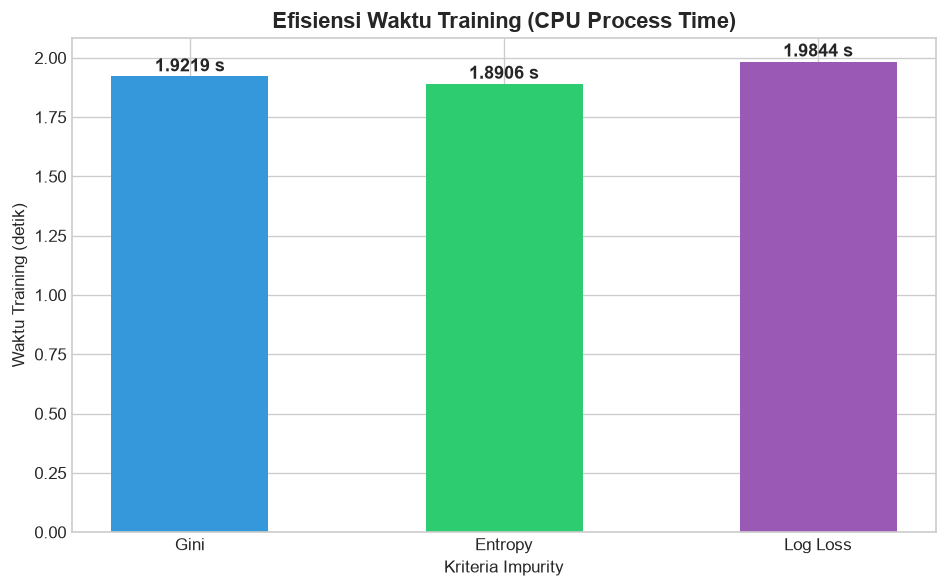

In [10]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    ['Gini', 'Entropy', 'Log Loss'],
    df_final_comparison['Training_Time_s'],
    color=['#3498db', '#2ecc71', '#9b59b6'],
    width=0.5
)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f"{yval:.4f} s", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Efisiensi Waktu Training (CPU Process Time)', fontsize=13, fontweight='bold')
plt.xlabel('Kriteria Impurity')
plt.ylabel('Waktu Training (detik)')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_time_comparison.png')
plt.show()

### 8.3 Dual Heatmap Confusion Matrix Model Champion

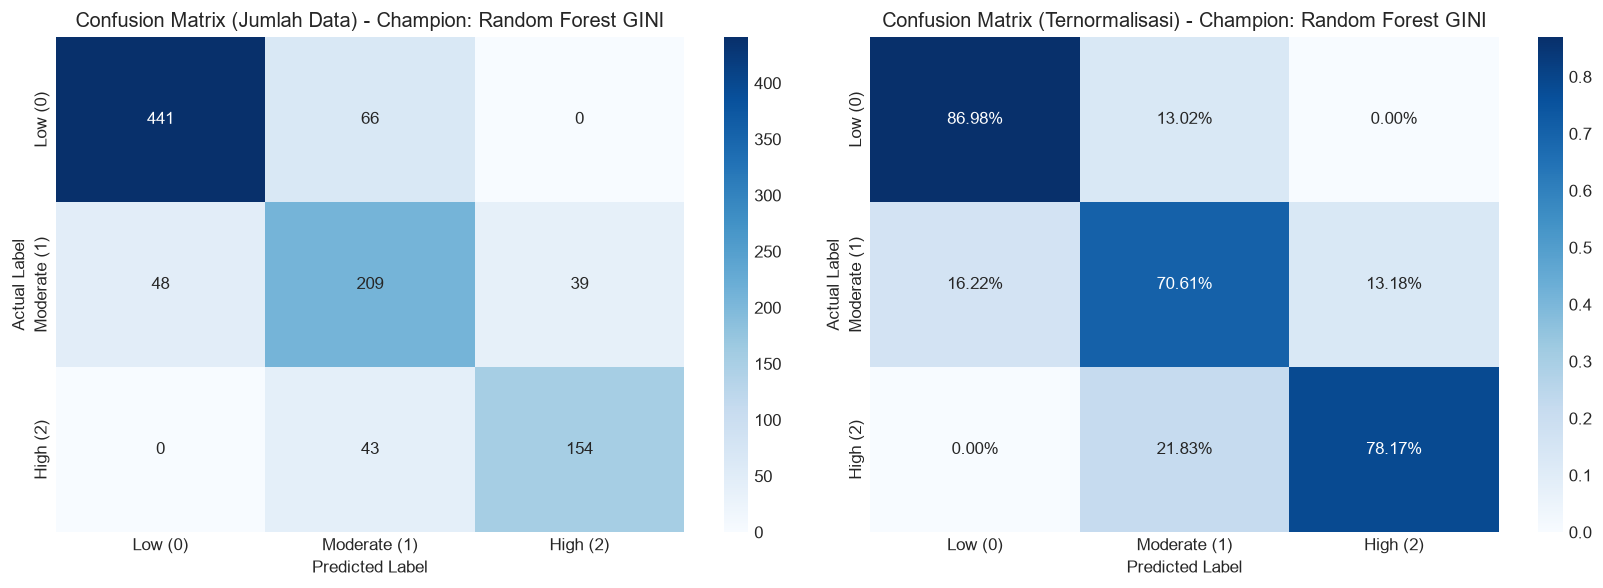

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Counts
sns.heatmap(
    champion_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[0]
)
axes[0].set_title(f'Confusion Matrix (Jumlah Data) - Champion: {champion_name}', fontsize=12)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Normalized Heatmap
cm_norm = champion_cm.astype('float') / champion_cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[1]
)
axes[1].set_title(f'Confusion Matrix (Ternormalisasi) - Champion: {champion_name}', fontsize=12)
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix_champion.png')
plt.show()

### 8.4 Top 10 Feature Importance Model Champion

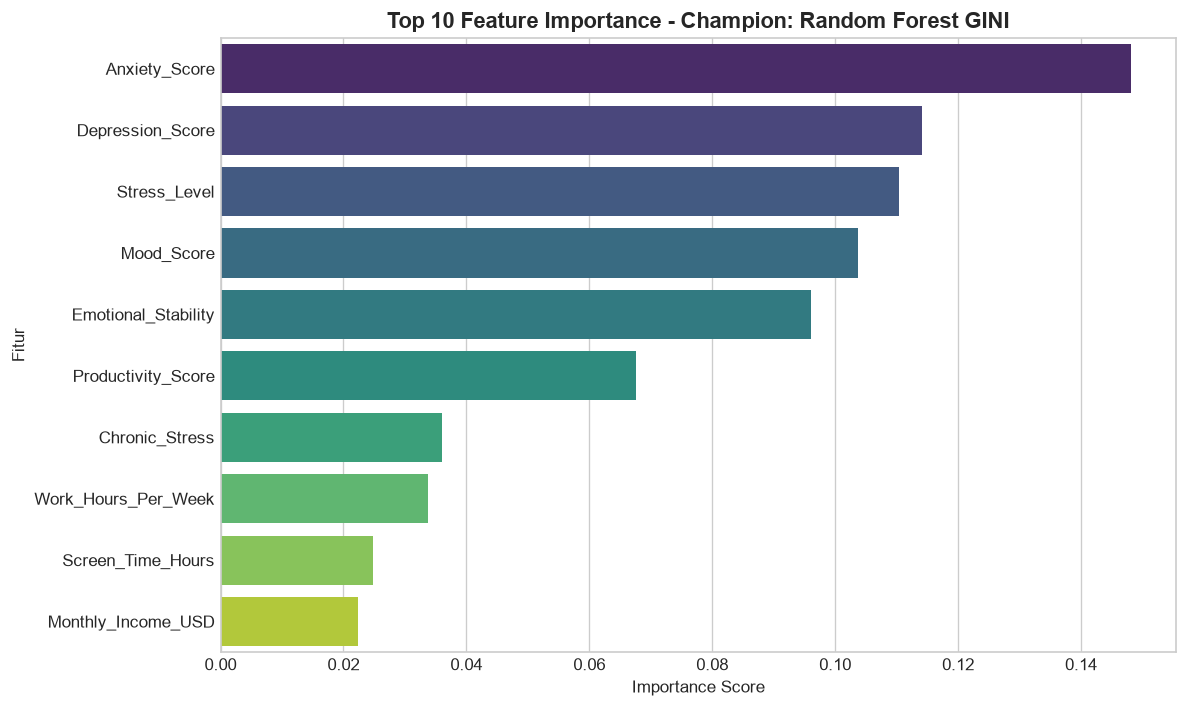

In [12]:
champion_model = fitted_models[champion_name]
champion_imp = pd.Series(champion_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=champion_imp.values, y=champion_imp.index, palette='viridis')
plt.title(f'Top 10 Feature Importance - Champion: {champion_name}', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/top10_feature_importance_champion.png')
plt.show()

### 8.5 Trade-off Akurasi vs Waktu Komputasi Training

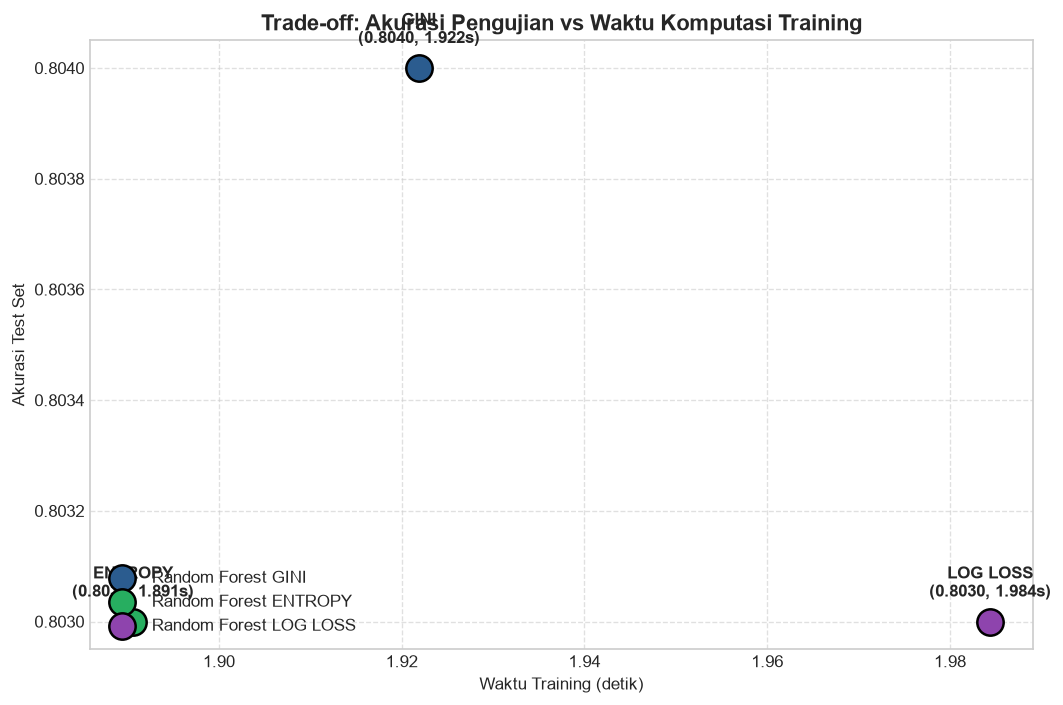

In [13]:
plt.figure(figsize=(9, 6))
colors = ['#2b5c8f', '#27ae60', '#8e44ad']

for i, row in df_final_comparison.iterrows():
    plt.scatter(
        row['Training_Time_s'],
        row['Test_Accuracy'],
        s=250,
        color=colors[i],
        label=row['Model'],
        edgecolors='black',
        linewidth=1.5,
        zorder=5
    )
    plt.annotate(
        f"{row['Model'].replace('Random Forest ', '')}\n({row['Test_Accuracy']:.4f}, {row['Training_Time_s']:.3f}s)",
        (row['Training_Time_s'], row['Test_Accuracy']),
        textcoords="offset points",
        xytext=(0, 15),
        ha='center',
        fontweight='bold',
        fontsize=10
    )

plt.title('Trade-off: Akurasi Pengujian vs Waktu Komputasi Training', fontsize=13, fontweight='bold')
plt.xlabel('Waktu Training (detik)')
plt.ylabel('Akurasi Test Set')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/tradeoff_accuracy_vs_time.png')
plt.show()

## 9. Kesimpulan & Rekomendasi Ilmiah

In [14]:
print('='*75)
print('KESIMPULAN DAN REKOMENDASI EKSPERIMEN RANDOM FOREST (PBL AntiBurnout)')
print('='*75)
print(f"1. Model Pemenang (Champion): {champion_name} dengan kriteria '{champion_criterion}'.")
print(f"   - Mean CV Accuracy (Training Set) : {champion_cv_acc:.4f}")
print(f"   - Final Test Accuracy (Holdout)   : {df_final_comparison.loc[df_final_comparison['Model']==champion_name, 'Test_Accuracy'].values[0]:.4f}")
print(f"   - Final Test F1-Macro             : {df_final_comparison.loc[df_final_comparison['Model']==champion_name, 'Test_F1_Macro'].values[0]:.4f}")

print('\n2. Perbandingan Karakteristik Algoritma:')
print('   - GINI Impurity: Menghitung 1 - sum(p_i^2). Komputasi paling efisien karena')
print('     tidak memerlukan operasi logaritma, sangat cocok untuk dataset dengan volume besar.')
print('   - SHANNON ENTROPY: Menghitung -sum(p_i * log2(p_i)). Cenderung menghasilkan pohon yang')
print('     lebih seimbang (balanced), sangat efektif untuk menangkap perbedaan ketidakpastian informasi.')
print('   - LOG LOSS: Menghitung -sum(p_i * ln(p_i)). Bersifat ekuivalen dengan Shannon entropy')
print('     namun berbasis logaritma natural (basis e), konsisten dengan multinomial logistic loss.')

print('\n3. Rekomendasi Deployment:')
print(f"   Model {champion_name} direkomendasikan sebagai arsitektur ensemble utama dalam")
print('   pipeline inferensi AntiBurnout karena memberikan akurasi generalisasi yang optimal')
print('   tanpa mengalami overfitting atau data leakage.')
print('='*75)

KESIMPULAN DAN REKOMENDASI EKSPERIMEN RANDOM FOREST (PBL AntiBurnout)
1. Model Pemenang (Champion): Random Forest GINI dengan kriteria 'gini'.
   - Mean CV Accuracy (Training Set) : 0.8092
   - Final Test Accuracy (Holdout)   : 0.8040
   - Final Test F1-Macro             : 0.7854

2. Perbandingan Karakteristik Algoritma:
   - GINI Impurity: Menghitung 1 - sum(p_i^2). Komputasi paling efisien karena
     tidak memerlukan operasi logaritma, sangat cocok untuk dataset dengan volume besar.
   - SHANNON ENTROPY: Menghitung -sum(p_i * log2(p_i)). Cenderung menghasilkan pohon yang
     lebih seimbang (balanced), sangat efektif untuk menangkap perbedaan ketidakpastian informasi.
   - LOG LOSS: Menghitung -sum(p_i * ln(p_i)). Bersifat ekuivalen dengan Shannon entropy
     namun berbasis logaritma natural (basis e), konsisten dengan multinomial logistic loss.

3. Rekomendasi Deployment:
   Model Random Forest GINI direkomendasikan sebagai arsitektur ensemble utama dalam
   pipeline inferensi Ant

## 10. Ekspor Artefak Komparasi

In [15]:
# Ekspor tabel perbandingan menyeluruh
df_final_comparison.to_csv(f'{OUTPUT_DIR}/tabel_perbandingan_random_forest.csv', index=False)

# Ekspor tabel 5-Fold CV comparison
df_cv_comparison.to_csv(f'{OUTPUT_DIR}/cv_5fold_comparison_random_forest.csv', index=False)

# Ekspor prediksi model champion
pd.DataFrame({
    'Actual': y_test,
    'Predicted': champion_pred
}, index=X_test.index).to_csv(f'{OUTPUT_DIR}/champion_predictions.csv')

# Ekspor Feature Importance Champion
champion_imp.to_frame(name='Importance').to_csv(f'{OUTPUT_DIR}/champion_feature_importance.csv')

print(f"Seluruh artefak komparasi berhasil diekspor ke folder: '{OUTPUT_DIR}/'")

Seluruh artefak komparasi berhasil diekspor ke folder: 'outputPerbandinganRandomForest/'
